# **Image informatics lab 2**

**1 Image Informatics - Lab 2**

**1.1 Histograms & Histogram Processing**

**Tasks:**
1. Plot the histograms of each of the R, G and B colour channels from an image. Plot each in
it corresponding colour and overlay them as a single image
2. Perform histogram equalization on each of the R, G and B colour channels from an image.

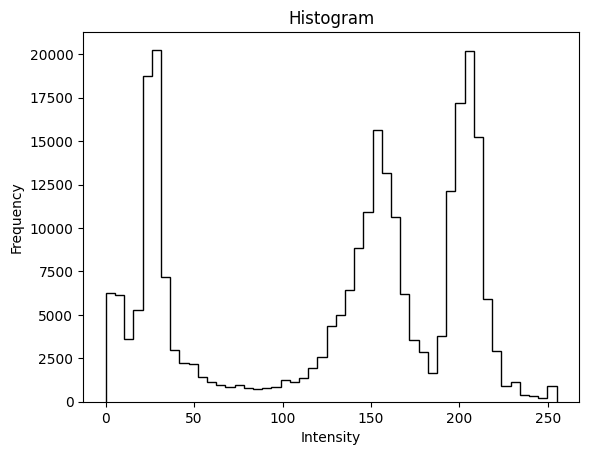

In [3]:
import numpy as np
from skimage import data
import matplotlib.pyplot as plt

im_camera = data.camera()
v = np.concatenate(im_camera)
bins = np.linspace(0, 255, 50)
p = plt.hist(v, bins, color='k', histtype='step')
t = plt.title("Histogram")
t = plt.xlabel('Intensity')
t = plt.ylabel('Frequency')

array([[[143, 120, 104],
        [143, 120, 104],
        [141, 118, 102],
        ...,
        [ 45,  27,  13],
        [ 45,  27,  13],
        [ 45,  27,  13]],

       [[146, 123, 107],
        [145, 122, 106],
        [143, 120, 104],
        ...,
        [ 46,  29,  13],
        [ 45,  29,  13],
        [ 47,  30,  14]],

       [[148, 126, 112],
        [147, 125, 111],
        [146, 122, 109],
        ...,
        [ 48,  28,  17],
        [ 49,  29,  18],
        [ 50,  30,  19]],

       ...,

       [[ 92,  58,  30],
        [105,  71,  43],
        [132,  98,  71],
        ...,
        [172, 145, 138],
        [172, 145, 138],
        [172, 145, 138]],

       [[128,  92,  60],
        [139, 103,  71],
        [134,  95,  64],
        ...,
        [166, 142, 132],
        [166, 142, 132],
        [167, 143, 133]],

       [[139, 103,  71],
        [127,  88,  57],
        [125,  86,  53],
        ...,
        [161, 137, 127],
        [161, 137, 127],
        [162, 138, 128]]], dtype=uint8)
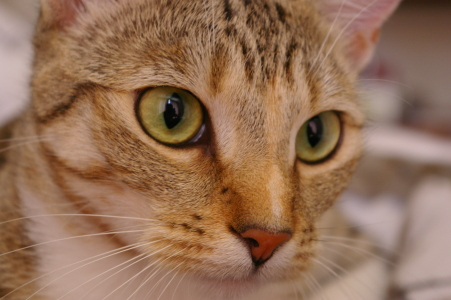

In [12]:
im_cat = data.cat()
im_cat

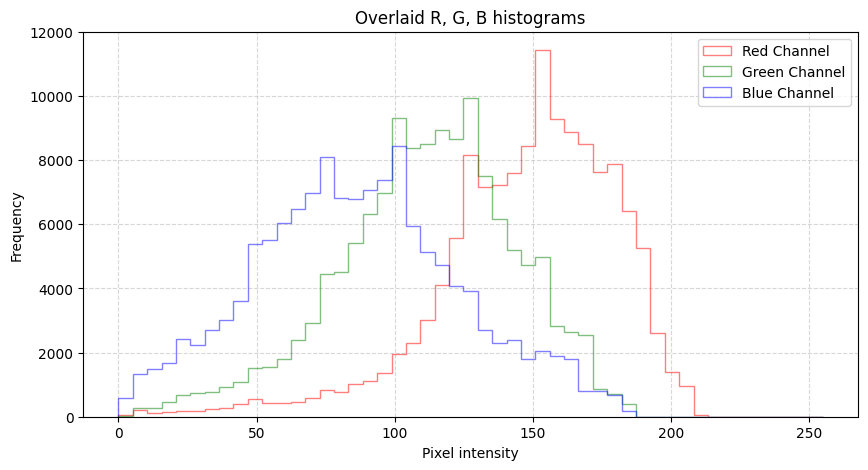

In [13]:
# Flatten the 2D channels to 1D vectors using .ravel()
#im_r, im_g, im_b = im_cat[:, :, 0].ravel(), im_cat[:, :, 1].ravel(), im_cat[:, :, 2].ravel()
im_r, im_g, im_b = im_cat[:, :, 0].flatten(), im_cat[:, :, 1].flatten(), im_cat[:, :, 2].flatten()

bins = np.linspace(0, 255, 50)

plt.figure(figsize =(10, 5))

plt.hist(im_r, bins = bins, color = 'red', histtype = 'step', alpha=0.5, label='Red Channel') #histtype = 'stepfilled'
plt.hist(im_g, bins = bins, color = 'green', histtype = 'step', alpha=0.5, label='Green Channel')
plt.hist(im_b, bins = bins, color = 'blue', histtype = 'step', alpha=0.5, label='Blue Channel')

plt.title("Overlaid R, G, B histograms")
plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

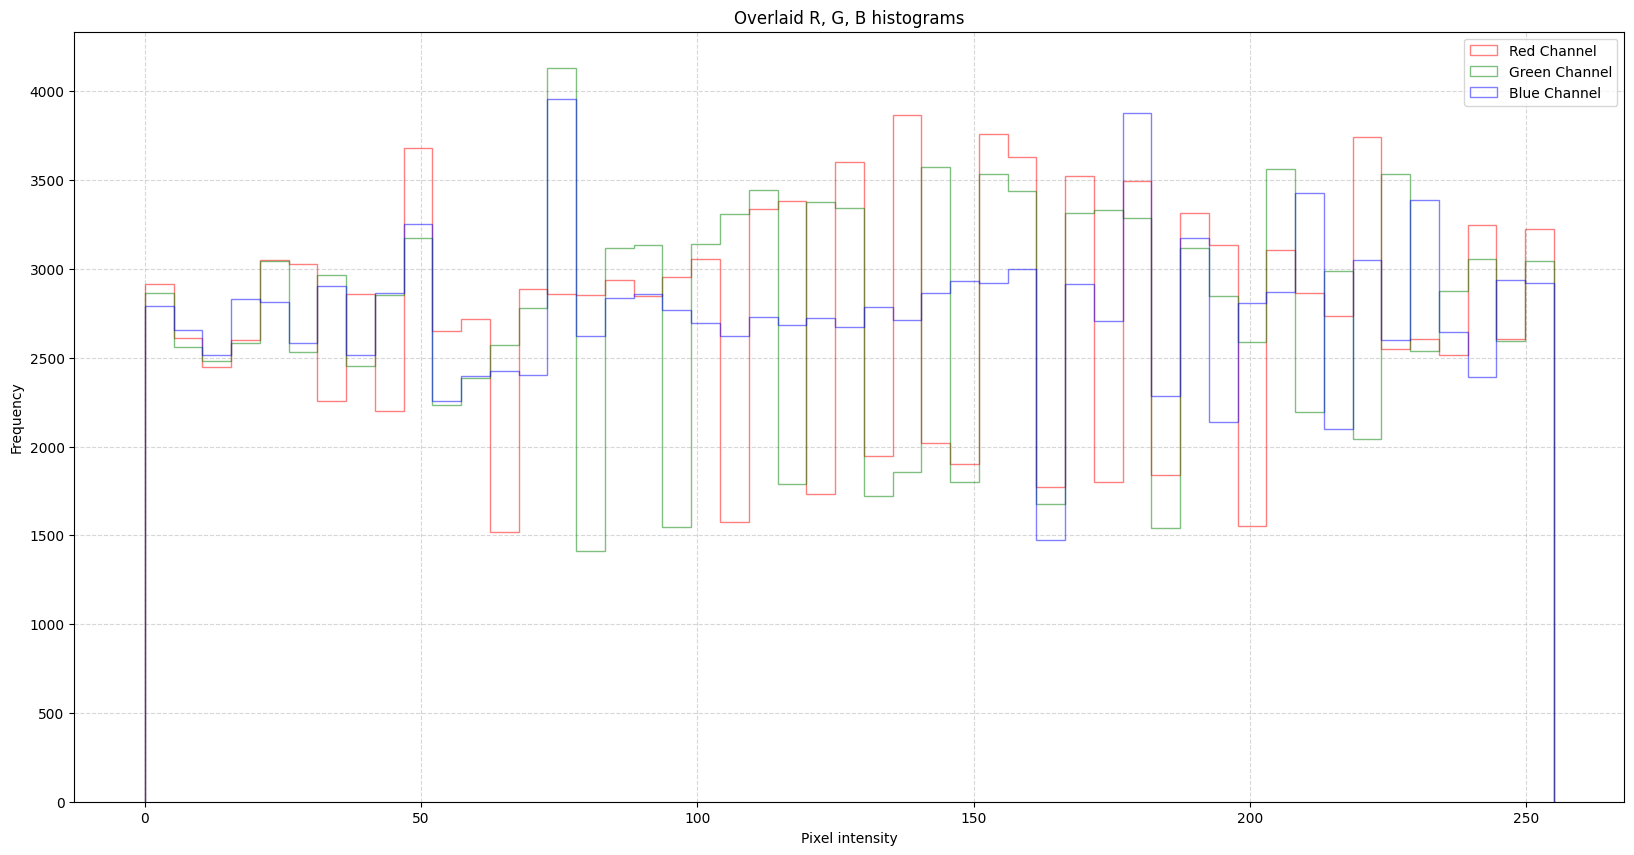

In [16]:
# Equalisation of channels
from skimage import io, data, img_as_ubyte
from skimage.exposure import equalize_hist, match_histograms

im_r, im_g, im_b = im_cat[:, :, 0].flatten(), im_cat[:, :, 1].flatten(), im_cat[:, :, 2].flatten()

im_r_eq = equalize_hist(im_r)
im_r = img_as_ubyte(im_r_eq)

im_g_eq = equalize_hist(im_g)
im_g = img_as_ubyte(im_g_eq)

im_b_eq = equalize_hist(im_b)
im_b = img_as_ubyte(im_b_eq)

bins = np.linspace(0, 255, 50)

plt.figure(figsize =(20, 10))

plt.hist(im_r, bins = bins, color = 'red', histtype = 'step', alpha=0.5, label='Red Channel') #histtype = 'stepfilled'
plt.hist(im_g, bins = bins, color = 'green', histtype = 'step', alpha=0.5, label='Green Channel')
plt.hist(im_b, bins = bins, color = 'blue', histtype = 'step', alpha=0.5, label='Blue Channel')

plt.title("Overlaid R, G, B histograms")
plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


**1.2 Colour Image Processing**

**Tasks:**
1. Separate out objects in the scene of a particular Hue value. Add these back as a colour overlay
onto the original image in grayscale as per the example of the rose (Hue = Red).
2. Perform Histogram Equalization on the V channel of an HSV version of a RGB colour image
before converting back to RGB for display. Compare this to just performing Histogram
Equalization on each channel of the RGB version of he image. Display both version in
different windows. The difference in result is also apparent for all contrast enhancement and
manipulation approaches.

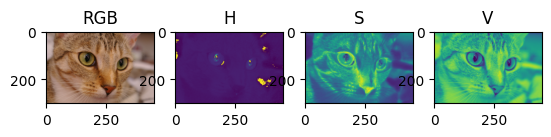

In [17]:
from skimage import data
from skimage.color import rgb2hsv
import matplotlib.pyplot as plt

im = data.chelsea()
im_hsv = rgb2hsv(im)
im_hsv_h = im_hsv[:,:,0]
im_hsv_s = im_hsv[:,:,1]
im_hsv_v = im_hsv[:,:,2]

fig = plt.figure()
ax = fig.add_subplot(1, 4, 1)
p = plt.imshow(im)
t = ax.set_title('RGB')

ax = fig.add_subplot(1, 4, 2)
p = plt.imshow(im_hsv_h)
t = ax.set_title('H')

ax = fig.add_subplot(1, 4, 3)
p = plt.imshow(im_hsv_s)
t = ax.set_title('S')

ax = fig.add_subplot(1, 4, 4)
p = plt.imshow(im_hsv_v)
t = ax.set_title('V')